# London Pulse · From workbook to moving city

**Research question:** How does estimated demand vary through a typical autumn weekday across London's rail stations and lines?

This notebook documents the main EDA and cleaning in **Python**. The Three.js app consumes the resulting data, not the spreadsheet. Source: TfL `NBT25TWT_Outputs.xlsx`. The filename indicates 2025 Tuesday–Thursday. This is a representative historical day, not a live feed.

The existing `01_explore.ipynb` remains unchanged. All workbook text is treated as data or documentation, never executable instructions.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import numpy as np
from IPython.display import display, Markdown, Image

ROOT = Path.cwd()
if not (ROOT / 'analysis').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from analysis.pipeline import PERIODS, clean_sheet, prepare_geography
from analysis.eda import run as build_eda
SOURCE = ROOT / 'data/raw/NBT25TWT_Outputs.xlsx'
book = pd.ExcelFile(SOURCE)
display(pd.DataFrame({'sheet': book.sheet_names}))

,sheet
0,_Cover
1,Link_Loads
2,Link_Frequencies
3,Line_Boarders
4,Station_Flows
5,Station_Entries
6,Station_Exits
7,Station_Boarders
8,Station_Alighters


## 1. Locate the actual schema

The first two rows describe hours and quarter-hours. Row 3 contains field names. Reading without `header=2` turns presentation labels into columns. We preserve the original file and import the real schema explicitly.

In [2]:
raw_entries = pd.read_excel(book, sheet_name='Station_Entries', header=2)
raw_lines = pd.read_excel(book, sheet_name='Line_Boarders', header=2)
display(raw_entries.iloc[:5, :8])
print(f"Station records: {len(raw_entries):,}; quarter-hour columns: {len(PERIODS)}")
display(raw_lines[['Mode', 'Line Code', 'Line Name', 'Total']].tail(4))

,NLC,ASC,Station,Fare Zone,Total,Early,AM Peak,Midday
0,750,ABRd,Abbey Road,2/3,2264.202420,193.739090,603.729488,710.115845
1,1404,ACCr,Acton Central,3,2653.556048,170.013170,902.876701,714.161923
2,3000,AMLr,Acton Main Line,3,6446.733500,477.467411,2435.414198,1779.666422
3,500,ACTu,Acton Town,3,7956.237201,455.893737,2729.790646,2429.717729
4,9441,ADVt,Addington Village,4,0.000000,0.000000,0.000000,0.000000


Station records: 471; quarter-hour columns: 96


,Mode,Line Code,Line Name,Total
17,LO,WEL,LO Lioness,4.636148e+04
18,TRM,TRM,London Trams,0.000000e+00
19,NaN,NaN,NaN,NaN
20,TfL,TfL,TOTAL,7.061268e+06


## 2. Clean without manufacturing demand

The reusable cleaning function removes empty formatting rows/columns, trims text, excludes the explicit `TOTAL` line row, validates numeric finite nonnegative values, and reconciles every daily total with 96 intervals. Missing demand is not filled with zero. Repeated platform IDs require a line in the key; ambiguous station-flow IDs are retained and reported.

In [3]:
entries, entries_audit = clean_sheet(raw_entries, 'Station_Entries')
lines, line_audit = clean_sheet(raw_lines, 'Line_Boarders')
quality = json.loads((ROOT / 'reports/quality_report.json').read_text())
display(pd.DataFrame(quality['sheets']).T[['clean_rows', 'key_definition', 'duplicate_keys', 'logical_duplicate_keys', 'exact_duplicate_rows', 'zero_total_rows', 'maximum_total_residual']])
print('Station-entry audit:', entries_audit)
print('Explicit line aggregates removed:', line_audit['aggregate_rows_removed'])

,clean_rows,key_definition,duplicate_keys,logical_duplicate_keys,exact_duplicate_rows,zero_total_rows,maximum_total_residual
Link_Loads,1214,Link,0,0,0,79,0.0
Link_Frequencies,1214,Link,0,0,0,79,0.0
Line_Boarders,19,Line Code,0,0,0,1,0.0
Station_Flows,5627,ID,28,28,13,558,0.0
Station_Entries,471,NLC,0,0,0,39,0.0
Station_Exits,471,NLC,0,0,0,39,0.0
Station_Boarders,1166,ID + Line,87,0,0,73,0.0
Station_Alighters,1166,ID + Line,87,0,0,73,0.0


Station-entry audit: {'source_rows': 471, 'clean_rows': 471, 'formatting_rows_removed': 0, 'aggregate_rows_removed': 0, 'duplicate_keys': 0, 'logical_duplicate_keys': 0, 'key_definition': 'NLC', 'exact_duplicate_rows': 0, 'used_in_app': True, 'missing_numeric_values': 0, 'negative_values': 0, 'zero_total_rows': 39, 'maximum_total_residual': 0.0}
Explicit line aggregates removed: 1


### Which duplicates are errors?

A shared platform may have separate boarding records for two lines. Those are distinct observations. In contrast, `Station_Flows` has both repeated rows and IDs with differing platform descriptions. No deletion rule is supported by the workbook alone, so those records retain source-row provenance and are excluded from map metrics.

In [4]:
platforms = pd.read_csv(ROOT / 'data/processed/station_boarders.csv.gz')
flows = pd.read_csv(ROOT / 'data/processed/station_flows.csv.gz')
print('Platform ID repeats:', platforms.ID.duplicated().sum())
print('Platform (ID, Line) repeats:', platforms.duplicated(['ID', 'Line']).sum())
assert not platforms.duplicated(['ID', 'Line']).any()
assert np.isclose(platforms.Total.sum(), lines.Total.sum(), atol=.001, rtol=0)
display(platforms.loc[platforms.ID.duplicated(False), ['ID', 'Station', 'Line', 'Total']].head(8))
display(flows.loc[flows.ID.duplicated(False), ['source_excel_row', 'ID', 'From Station', 'To Station', 'Movement', 'Total']].head(6))

Platform ID repeats: 87
Platform (ID, Line) repeats: 0


,ID,Station,Line,Total
12,10624,Aldgate,HAM,2429.141378
14,10624,Aldgate,MET,8805.471698
15,10816,Aldgate East,DIS,4914.765368
16,10817,Aldgate East,DIS,12018.699956
17,10816,Aldgate East,HAM,1356.817498
18,10817,Aldgate East,HAM,6878.700784
53,11316,Bank and Monument,DIS,8506.450339
54,11317,Bank and Monument,DIS,13484.371634


,source_excel_row,ID,From Station,To Station,Movement,Total
590,594,170130>170472,Caledonian Road,Caledonian Road & Barnsbury,Alight-Exit-Interchange-Enter-Board,104.388774
591,595,170131>170473,Caledonian Road,Caledonian Road & Barnsbury,Alight-Exit-Interchange-Enter-Board,87.917293
592,596,170130>170472,Caledonian Road,Caledonian Road & Barnsbury,Alight-Exit-Interchange-Enter-Board,104.388774
593,597,170131>170473,Caledonian Road,Caledonian Road & Barnsbury,Alight-Exit-Interchange-Enter-Board,87.917293
1959,1963,190283>190280,King's Cross,St. Pancras International,Alight-Exit-Interchange-Enter-Board,0.000000
1965,1969,190283>190280,King's Cross,King's Cross,Alight-Exit-Interchange-Enter-Board,0.000000


## 3. Keep the traffic day in order

The day is 05:00 to 04:59 the next morning. Sorting text times puts midnight first and corrupts the chronology. We use `interval_index` and elapsed minutes from 05:00. Decimals are estimates, not a reason to round during cleaning.

In [5]:
time_axis = pd.DataFrame({'interval_index': range(96), 'interval': PERIODS})
time_axis['minutes_since_traffic_day_start'] = time_axis.interval_index * 15
time_axis['next_calendar_day'] = time_axis.interval_index >= 76
display(time_axis.iloc[73:80])
tidy = pd.read_csv(ROOT / 'data/processed/station_demand_tidy.csv.gz')
assert len(tidy) == len(entries) * 96
assert not tidy.duplicated(['NLC', 'interval']).any()
print(f'{len(tidy):,} tidy station–interval observations')
display(tidy.head(4))

,interval_index,interval,minutes_since_traffic_day_start,next_calendar_day
73,73,2315-2330,1095,False
74,74,2330-2345,1110,False
75,75,2345-0000,1125,False
76,76,0000-0015,1140,True
77,77,0015-0030,1155,True
78,78,0030-0045,1170,True
79,79,0045-0100,1185,True


45,216 tidy station–interval observations


,NLC,ASC,Station,Fare Zone,interval,entries,exits,interval_index,minutes_since_traffic_day_start,next_calendar_day
0,750,ABRd,Abbey Road,2/3,0500-0515,3.464569,0.659086,0,0,False
1,1404,ACCr,Acton Central,3,0500-0515,0.000000,0.000000,0,0,False
2,3000,AMLr,Acton Main Line,3,0500-0515,15.221997,1.933374,0,0,False
3,500,ACTu,Acton Town,3,0500-0515,10.941830,1.317754,0,0,False


## 4. Audit geographic coverage

The workbook has no latitude/longitude. Join the versioned station reference by NLC. The original reference repeats Hayes & Harlington's 3186 code for Headstone Lane. Correct only Headstone Lane to 1434. Custom House EL has no separate reference row and uses a labelled DLR station-complex proxy. The original reference is retained.

In [6]:
locations = prepare_geography(ROOT / 'data/external/stations_source.csv', entries)
assert locations[['x', 'y']].notna().all().all()
assert locations.NLC.is_unique
print(f'{len(locations)} / {len(entries)} station records matched')
display(locations.loc[locations.NLC.isin([1434,3186,6561])])
zero = entries.loc[entries.Total.eq(0), ['NLC', 'Station', 'Total']]
print(f'{len(zero)} zero-total records retained; {entries.Total.gt(0).sum()} active rail records')
display(zero.head())

471 / 471 station records matched


,NLC,ASC,Station,Fare Zone,x,y,coordinate_method
189,3186,HAYr,Hayes & Harlington,5,-0.420642,51.503048,reference NLC match
190,1434,HDLr,Headstone Lane,5,-0.355652,51.602098,reference NLC match
468,6561,CUSr,Custom House EL,3,0.028149,51.509223,Custom House DLR complex proxy


39 zero-total records retained; 432 active rail records


,NLC,Station,Total
4,9441,Addington Village,0.0
5,9440,Addiscombe,0.0
11,9442,Ampere Way,0.0
15,9443,Arena,0.0
18,9444,Avenue Road,0.0


## 5. Explore volume and timing

Compare station entries with exits, identify the maximum quarter-hour, and rank station entry records. Entries and exits are separate measures and are not forced to balance. Line boardings count transfers. Link sums count passenger-segments, not unique journeys.

,value
daily_entries,5182759.967438
daily_exits,5186806.492025
entry_exit_difference,4046.524587
top10_entry_share,0.205281
peak_interval,1730-1745
peak_entries,140479.645004
am_peak_entries_0700_1000,1265270.482191
pm_peak_entries_1600_1900,1406794.827988
pm_to_am_ratio,1.111853
busiest_line,Northern


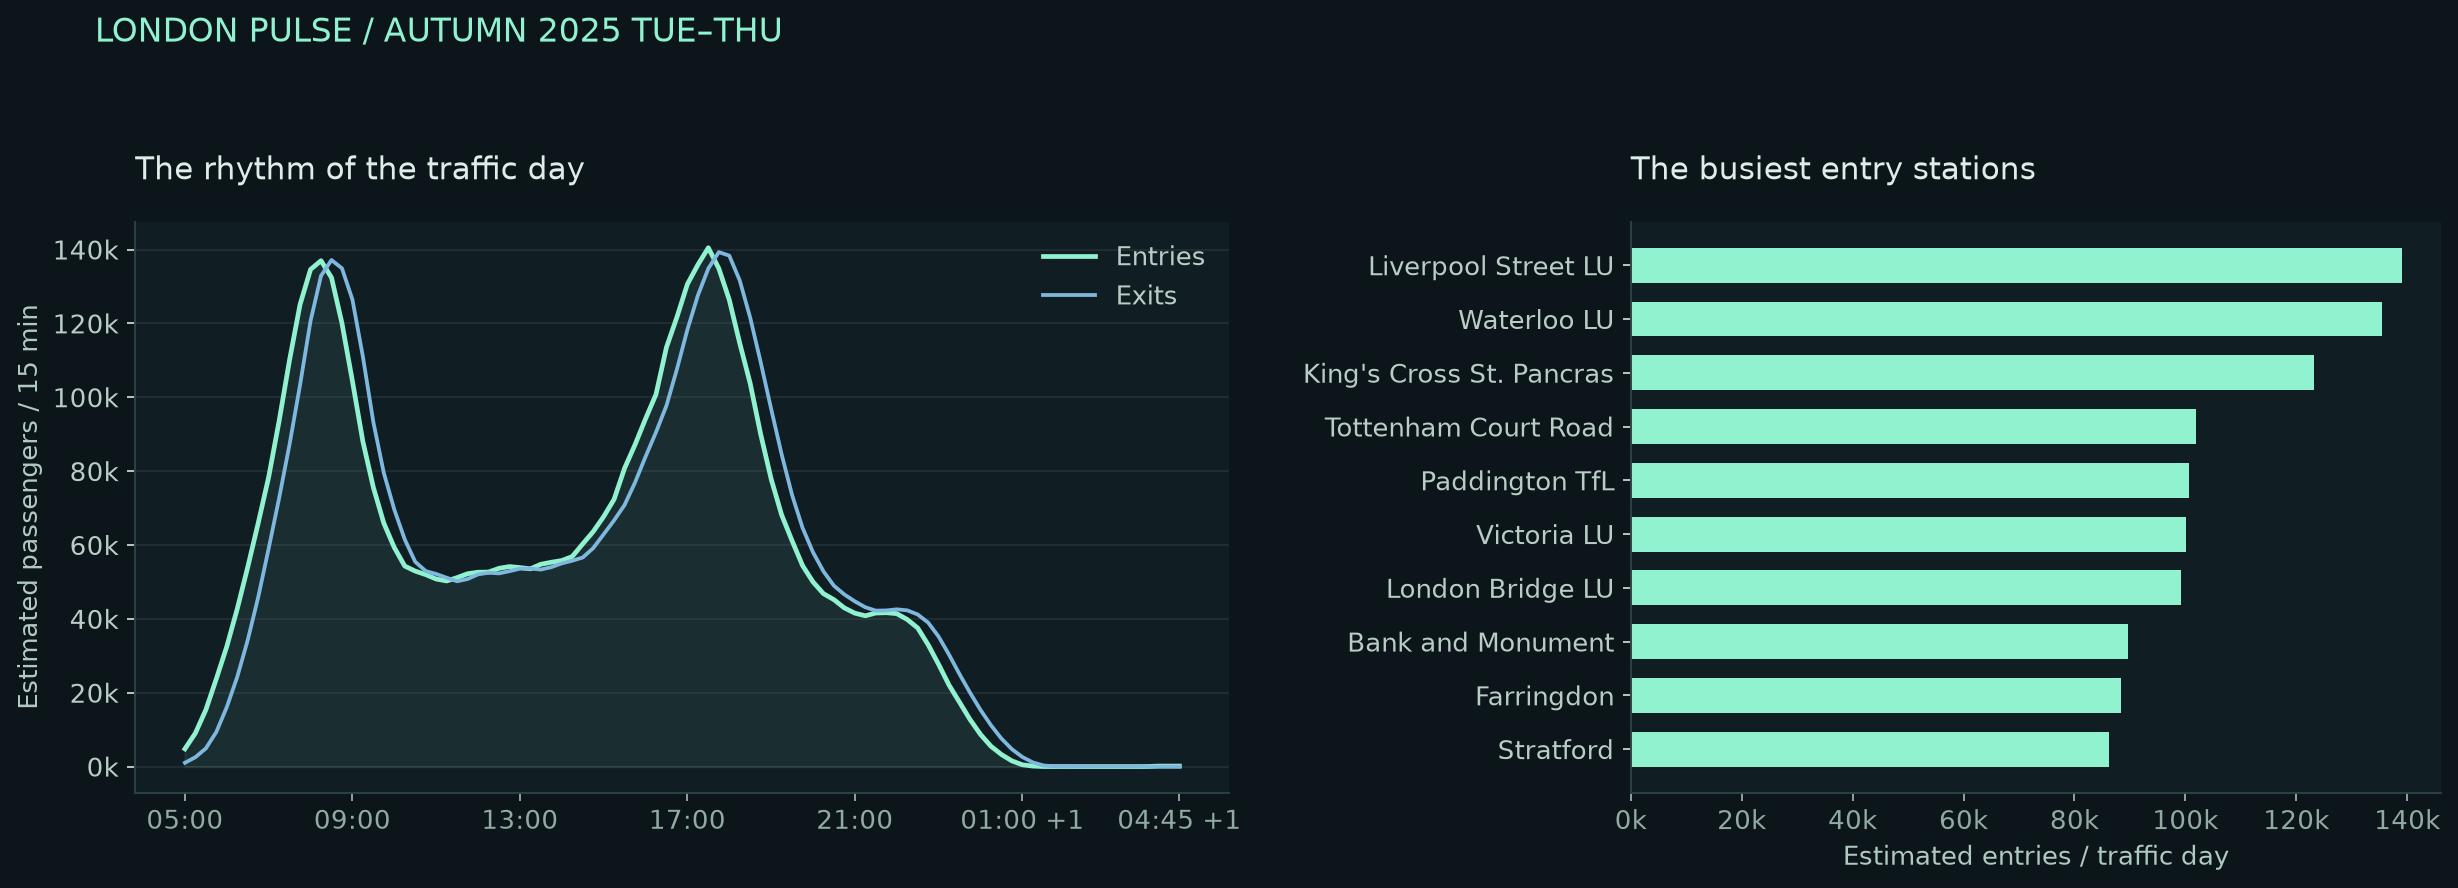

The network records **5,182,760 entries** and peaks at **1730-1745**. The top ten station records contribute **20.5%** of daily entries. The evening window (16:00–19:00) has **1.11×** the entries of 07:00–10:00.

In [7]:
summary = build_eda(ROOT)
display(pd.Series(summary, name='value').to_frame())
display(Image(filename=str(ROOT / 'reports/figures/demand_overview.png')))
display(Markdown(f"The network records **{summary['daily_entries']:,.0f} entries** and peaks at **{summary['peak_interval']}**. The top ten station records contribute **{summary['top10_entry_share']:.1%}** of daily entries. The evening window (16:00–19:00) has **{summary['pm_to_am_ratio']:.2f}×** the entries of 07:00–10:00."))

## 6. Compare line profiles fairly

The heatmap divides each line's quarter-hour boardings by its own daily maximum. This exposes timing differences without allowing larger lines to overwhelm the display. It must not be used to compare absolute volumes.

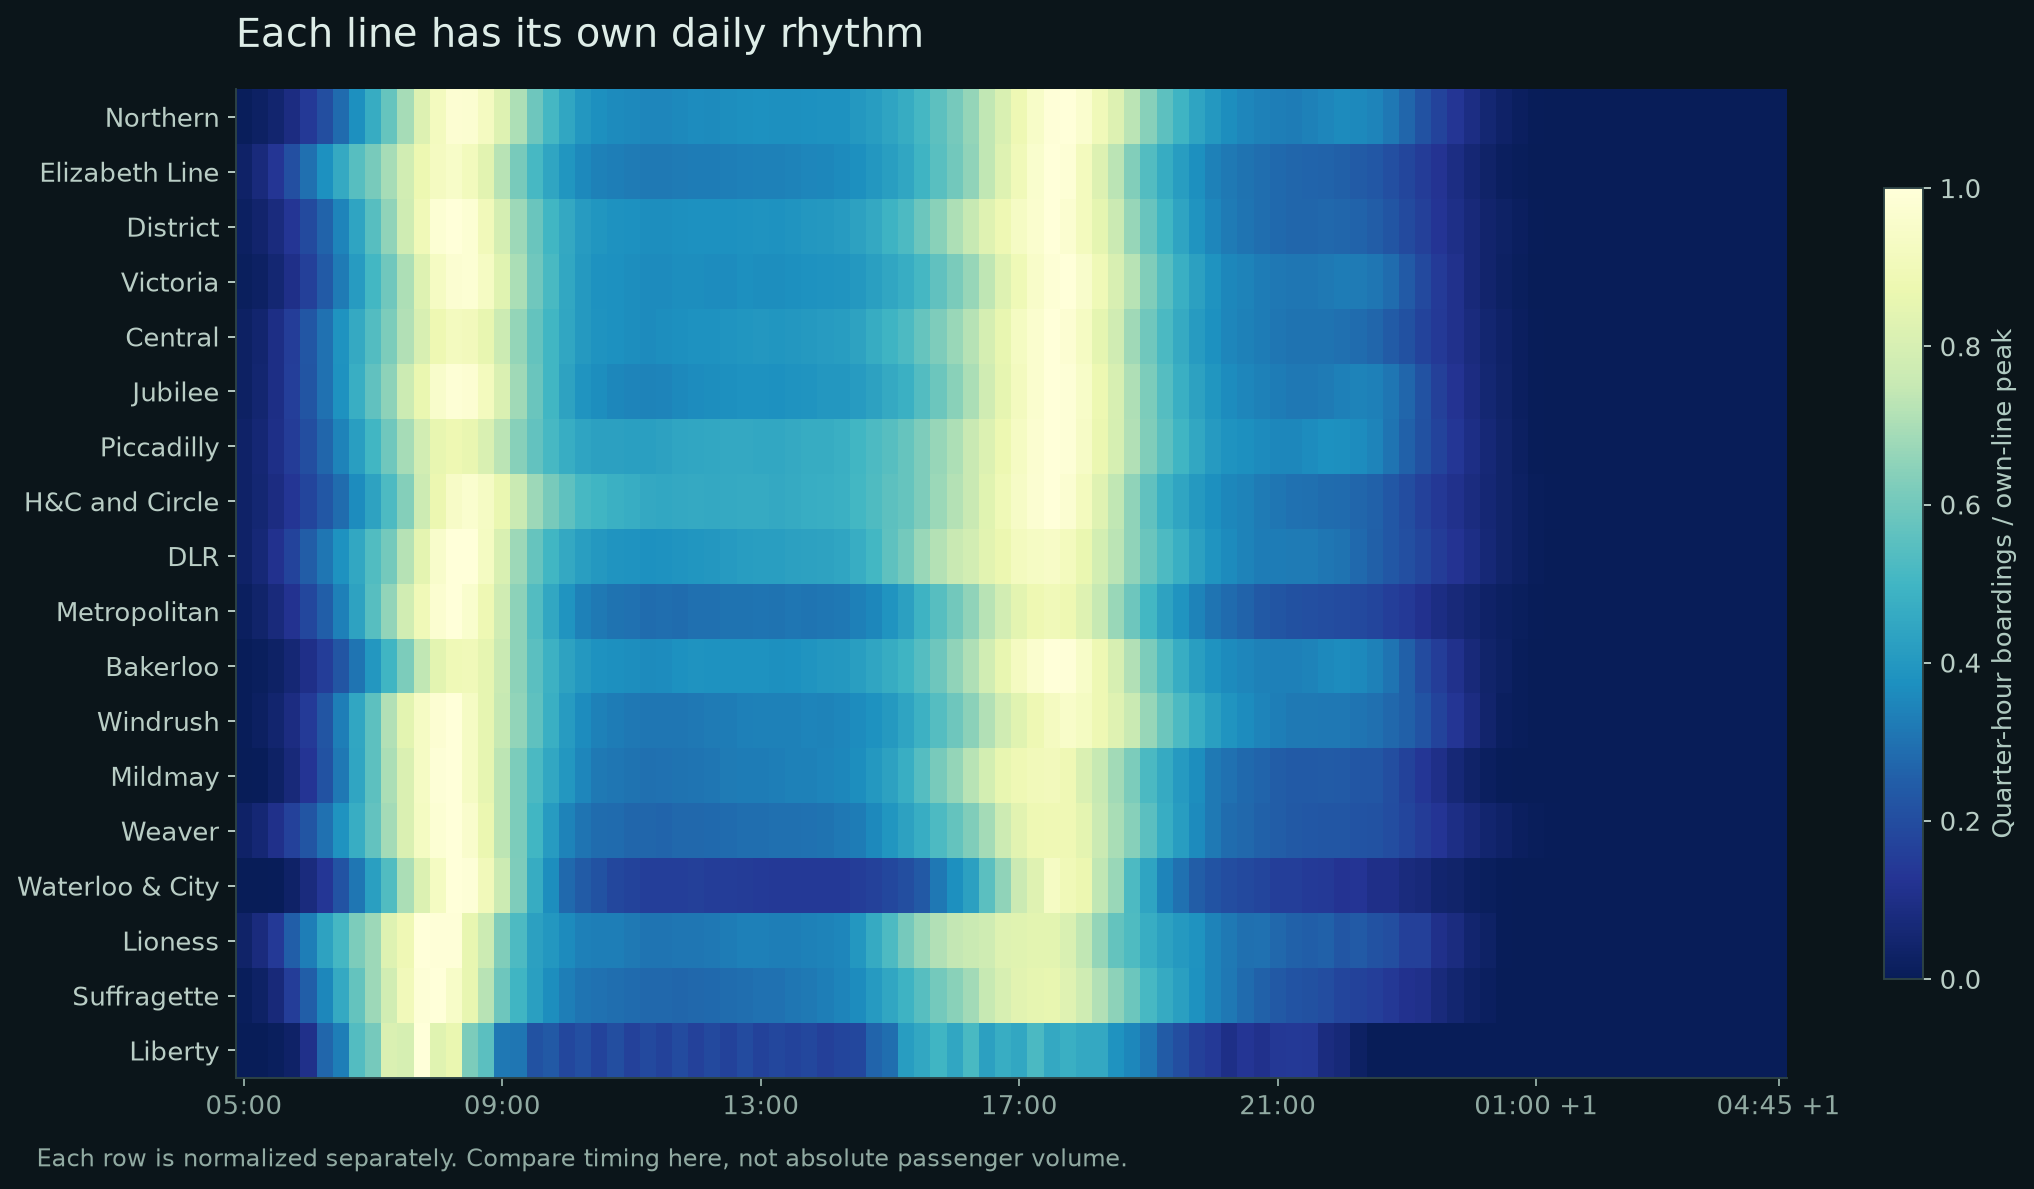

,Line Name,Total
6,Northern,977555.887793
11,Elizabeth Line,837560.924769
2,District,725014.287664
8,Victoria,708636.537062
1,Central,683452.731272
4,Jubilee,672932.334844
7,Piccadilly,491358.003203
3,H&C and Circle,411039.139904


In [8]:
display(Image(filename=str(ROOT / 'reports/figures/line_rhythms.png')))
display(lines.loc[lines.Total.gt(0), ['Line Name', 'Total']].sort_values('Total', ascending=False).head(8))

## 7. Where do entries exceed exits?

Compute entries minus exits in the source-defined AM/PM peaks. Positive values indicate more entries than exits. These are descriptive patterns: this dataset alone cannot identify employment destinations or prove why people travel.

In [9]:
balance = pd.read_csv(ROOT / 'reports/station_peak_balance.csv')
display(balance.nlargest(6, 'am_net_entries')[['Station','am_net_entries','pm_net_entries']])
display(balance.nsmallest(6, 'am_net_entries')[['Station','am_net_entries','pm_net_entries']])
display(pd.read_csv(ROOT / 'reports/top_directed_links.csv').head(5))

,Station,am_net_entries,pm_net_entries
425,Waterloo LU,21280.558692,-14539.678912
467,Abbey Wood,10967.392923,-9472.094969
53,Brixton LU,10015.612830,-5300.337709
149,Finsbury Park LU,8978.974493,-5209.617293
92,Clapham Junction,8820.339461,-4494.288295
469,Woolwich EL,7624.214907,-4047.704552


,Station,am_net_entries,pm_net_entries
21,Bank and Monument,-44178.452817,31037.157989
144,Farringdon,-29494.530442,22929.521750
298,Oxford Circus,-28360.067926,9740.661542
250,Liverpool Street LU,-27629.356893,20739.765295
397,Tottenham Court Road,-26572.924898,11536.287249
251,Liverpool Street NR,-26082.645106,20581.017391


,Line,Dir,From Station,To Station,Total
0,Elizabeth Line,EB,Farringdon,Liverpool Street LU,193615.357806
1,Elizabeth Line,WB,Liverpool Street LU,Farringdon,190408.065516
2,Elizabeth Line,WB,Whitechapel,Liverpool Street LU,189670.897541
3,Elizabeth Line,EB,Liverpool Street LU,Whitechapel,187766.675746
4,Elizabeth Line,EB,Tottenham Court Road,Farringdon,184833.238038


## 8. Browser contract and analytical limits

The browser uses a compact JSON containing station vectors, directed links, line profiles and provenance. Values are rounded to three decimals only at export. Displayed metrics round estimated values to whole passengers. Fixed network-wide square-root scaling supports comparisons across time; particles illustrate relative demand and do not represent actual train positions or travel speeds.

**Limits:** representative autumn day; scheduled service assumption; estimated route choice; uncertain interchange paths; separate NLCs within complexes; 39 zero-total tram records; an older geographic reference; one location proxy. No inference about live delays, capacity, unique individuals, annual trends or causal effects is justified.

In [10]:
payload = json.loads((ROOT / 'public/data/network.json').read_text())
assert len(payload['intervals']) == 96
assert all(len(s['entries']) == 96 for s in payload['stations'])
assert all(len(l['values']) == 96 for l in payload['links'])
exported_total = sum(s['dailyEntries'] for s in payload['stations'])
assert abs(exported_total - entries.Total.sum()) < 1
print('Browser data contract verified.')
print('Raw workbook SHA-256:', payload['meta']['sourceSha256'])
print('Prepared outputs: data/processed/, reports/, public/data/')

Browser data contract verified.
Raw workbook SHA-256: a10e5f767750538ecac99cf0d2131243672574df88b9c933f03b9357c5f67db2
Prepared outputs: data/processed/, reports/, public/data/
